# PTB-XL ECG Data Processing & Exploration

**Goal:** Multi-label classification of 12-lead ECG signals into 5 diagnostic superclasses:
- **NORM** – Normal ECG
- **MI** – Myocardial Infarction
- **STTC** – ST/T Change
- **CD** – Conduction Disturbance
- **HYP** – Hypertrophy

**Data:** PTB-XL v1.0.3 — 100 Hz downsampled signals (12 leads, 1000 samples = 10s)

**Split strategy (mandatory):** Folds 1–8 → Train | Fold 9 → Validation | Fold 10 → Test

In [8]:
#%pip install wfdb

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import ast
import wfdb
from collections import Counter
from tqdm import tqdm

import warnings
warnings.filterwarnings("ignore")

print("Libraries loaded ✓")

Libraries loaded ✓


In [43]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [46]:
drive_path = 'drive/MyDrive/ECG'
os.listdir(drive_path)

['DATA', 'models']

In [11]:
# PTB ECG dataset
import kagglehub

path_ptb = kagglehub.dataset_download("garethwmch/ptb-xl-1-0-3")

print("Path to dataset files:", path_ptb)

100%|██████████| 1.72G/1.72G [00:23<00:00, 79.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/garethwmch/ptb-xl-1-0-3/versions/1


In [12]:
# PTB-XL+

path_ptb_plus = kagglehub.dataset_download("bjoernjostein/ptb-xl")

print("Path to dataset files:", path_ptb_plus)

100%|██████████| 727M/727M [00:04<00:00, 155MB/s]  

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/bjoernjostein/ptb-xl/versions/1


In [16]:
PATH_PTB = os.path.join(path_ptb, 'ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3')
os.listdir(PATH_PTB)

['scp_statements.csv',
 'example_physionet.py',
 'records100',
 'SHA256SUMS.txt',
 'RECORDS',
 'LICENSE.txt',
 'ptbxl_database.csv',
 'records500',
 'ptbxl_v103_changelog.txt',
 'ptbxl_v102_changelog.txt']

In [18]:
PATH_PTB_PLUS = os.path.join(path_ptb_plus, 'ptb-xl-a-comprehensive-electrocardiographic-feature-dataset-1.0.1')
os.listdir(PATH_PTB_PLUS)

['features',
 'fiducial_points',
 'SHA256SUMS.txt',
 'RECORDS',
 'LICENSE.txt',
 'median_beats',
 'labels']

In [19]:
# Load the main database
df = pd.read_csv(os.path.join(PATH_PTB, "ptbxl_database.csv"), index_col="ecg_id")
print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
df.head(3)

Dataset shape: (21799, 27)
Columns: ['patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']


,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr


In [20]:
# Basic info
print(f"Total records: {len(df)}")
print(f"\nMissing values:\n{df.isnull().sum()[df.isnull().sum() > 0]}")
print(f"\nAge stats:\n{df['age'].describe()}")
print(f"\nSex distribution (0=female, 1=male):\n{df['sex'].value_counts()}")
print(f"\nFold distribution:\n{df['strat_fold'].value_counts().sort_index()}")

Total records: 21799

Missing values:
height                 14825
weight                 12378
nurse                   1473
site                      17
heart_axis              8468
infarction_stadium1    16187
infarction_stadium2    21696
validated_by            9378
baseline_drift         20201
static_noise           18539
burst_noise            21186
electrodes_problems    21769
extra_beats            19850
pacemaker              21508
dtype: int64

Age stats:
count    21799.000000
mean        62.769301
std         32.308813
min          2.000000
25%         50.000000
50%         62.000000
75%         72.000000
max        300.000000
Name: age, dtype: float64

Sex distribution (0=female, 1=male):
sex
0    11354
1    10445
Name: count, dtype: int64

Fold distribution:
strat_fold
1     2175
2     2181
3     2192
4     2174
5     2174
6     2173
7     2176
8     2173
9     2183
10    2198
Name: count, dtype: int64


## 1. Load & Parse SCP Statements → Diagnostic Superclasses

In [26]:
# Load SCP statement reference table
scp_df = pd.read_csv(os.path.join(PATH_PTB, "scp_statements.csv"), index_col=0)

# Keep only diagnostic statements
scp_diag = scp_df[scp_df["diagnostic"] == 1.0]
print(f"Total SCP statements: {len(scp_df)}")
print(f"Diagnostic statements: {len(scp_diag)}")
print(f"\nDiagnostic superclasses:\n{scp_diag['diagnostic_class'].value_counts()}")
scp_diag[["description", "diagnostic_class", "diagnostic_subclass"]].head(10)

Total SCP statements: 71
Diagnostic statements: 44

Diagnostic superclasses:
diagnostic_class
MI      14
STTC    13
CD      11
HYP      5
NORM     1
Name: count, dtype: int64


,description,diagnostic_class,diagnostic_subclass
NDT,non-diagnostic T abnormalities,STTC,STTC
NST_,non-specific ST changes,STTC,NST_
DIG,digitalis-effect,STTC,STTC
LNGQT,long QT-interval,STTC,STTC
NORM,normal ECG,NORM,NORM
IMI,inferior myocardial infarction,MI,IMI
ASMI,anteroseptal myocardial infarction,MI,AMI
LVH,left ventricular hypertrophy,HYP,LVH
LAFB,left anterior fascicular block,CD,LAFB/LPFB
ISC_,non-specific ischemic,STTC,ISC_


In [27]:
# Parse scp_codes column from string to dict
df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)

# Map each record to its diagnostic superclass labels
# A code maps to a superclass only if it's a diagnostic code with likelihood > 0
def aggregate_diagnostic_superclass(scp_dict, scp_ref):
    """Return set of superclass labels for one record."""
    labels = set()
    for code, likelihood in scp_dict.items():
        if code in scp_ref.index and likelihood > 0:
            superclass = scp_ref.loc[code, "diagnostic_class"]
            if pd.notna(superclass):
                labels.add(superclass)
    return labels

df["diagnostic_superclass"] = df["scp_codes"].apply(
    lambda x: aggregate_diagnostic_superclass(x, scp_diag)
)

# Create binary columns for the 5 target superclasses
SUPERCLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
for sc in SUPERCLASSES:
    df[sc] = df["diagnostic_superclass"].apply(lambda x: 1 if sc in x else 0)

# Show label distribution
print("Label counts (multi-label):")
print(df[SUPERCLASSES].sum().sort_values(ascending=False))
print(f"\nRecords with at least one label: {(df[SUPERCLASSES].sum(axis=1) > 0).sum()}")
print(f"Records with NO diagnostic label: {(df[SUPERCLASSES].sum(axis=1) == 0).sum()}")
print(f"\nLabel combinations (top 10):")
df["label_combo"] = df[SUPERCLASSES].apply(lambda row: tuple(row.values), axis=1)
print(df["label_combo"].value_counts().head(10))

ValueError: malformed node or string: {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}

## 2. Visualize Label Distribution

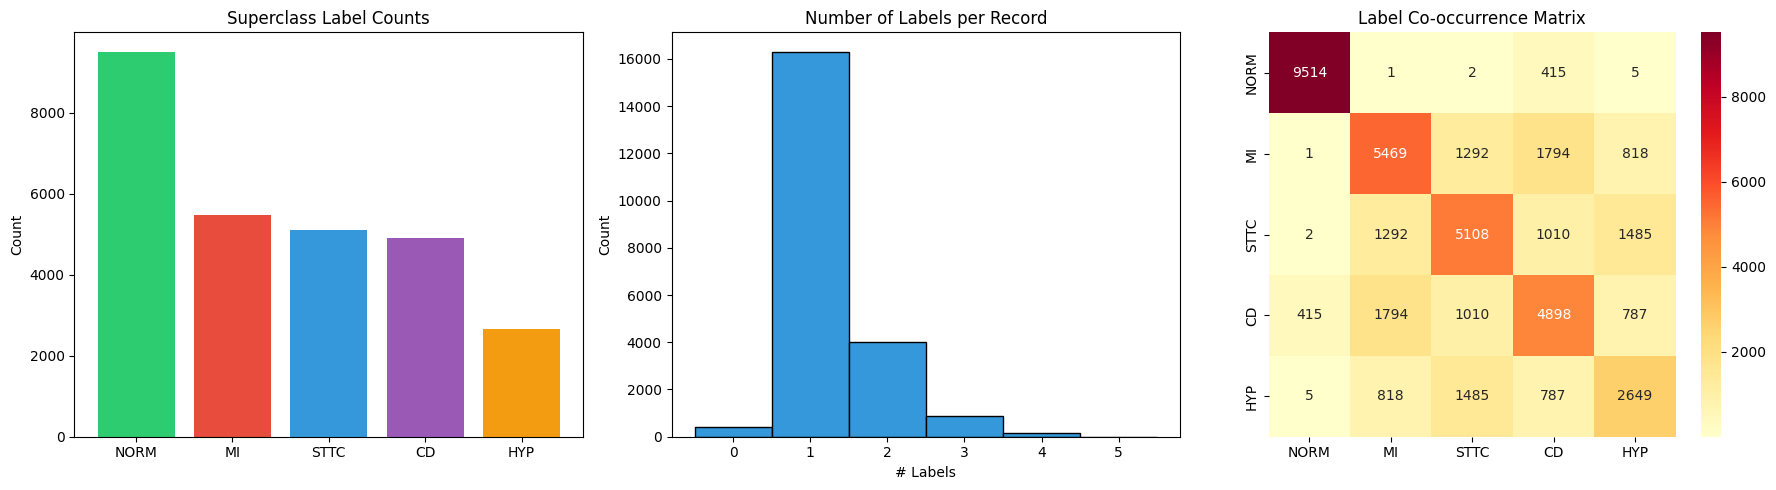

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1 - Superclass counts
counts = df[SUPERCLASSES].sum().sort_values(ascending=False)
axes[0].bar(counts.index, counts.values, color=["#2ecc71", "#e74c3c", "#3498db", "#9b59b6", "#f39c12"])
axes[0].set_title("Superclass Label Counts")
axes[0].set_ylabel("Count")

# 2 - Number of labels per record
n_labels = df[SUPERCLASSES].sum(axis=1)
axes[1].hist(n_labels, bins=range(0, 7), edgecolor="black", align="left", color="#3498db")
axes[1].set_title("Number of Labels per Record")
axes[1].set_xlabel("# Labels")
axes[1].set_ylabel("Count")

# 3 - Co-occurrence matrix
cooccurrence = df[SUPERCLASSES].T @ df[SUPERCLASSES]
sns.heatmap(cooccurrence, annot=True, fmt="d", cmap="YlOrRd", ax=axes[2])
axes[2].set_title("Label Co-occurrence Matrix")

plt.tight_layout()
plt.show()

## 3. Load ECG Signals (100 Hz)

In [29]:
def load_ecg_signal(filename, base_path, sampling_rate=100):
    """Load a single ECG signal using wfdb. Returns numpy array (1000, 12)."""
    full_path = os.path.join(base_path, filename)
    record = wfdb.rdrecord(full_path)
    return record.p_signal  # shape: (samples, 12)

# Test with first record
sample_signal = load_ecg_signal(df.iloc[0]["filename_lr"], PATH_PTB)
print(f"Signal shape: {sample_signal.shape}")
print(f"Leads: I, II, III, AVR, AVL, AVF, V1, V2, V3, V4, V5, V6")
print(f"Duration: {sample_signal.shape[0] / 100:.1f}s at 100 Hz")

Signal shape: (1000, 12)
Leads: I, II, III, AVR, AVL, AVF, V1, V2, V3, V4, V5, V6
Duration: 10.0s at 100 Hz


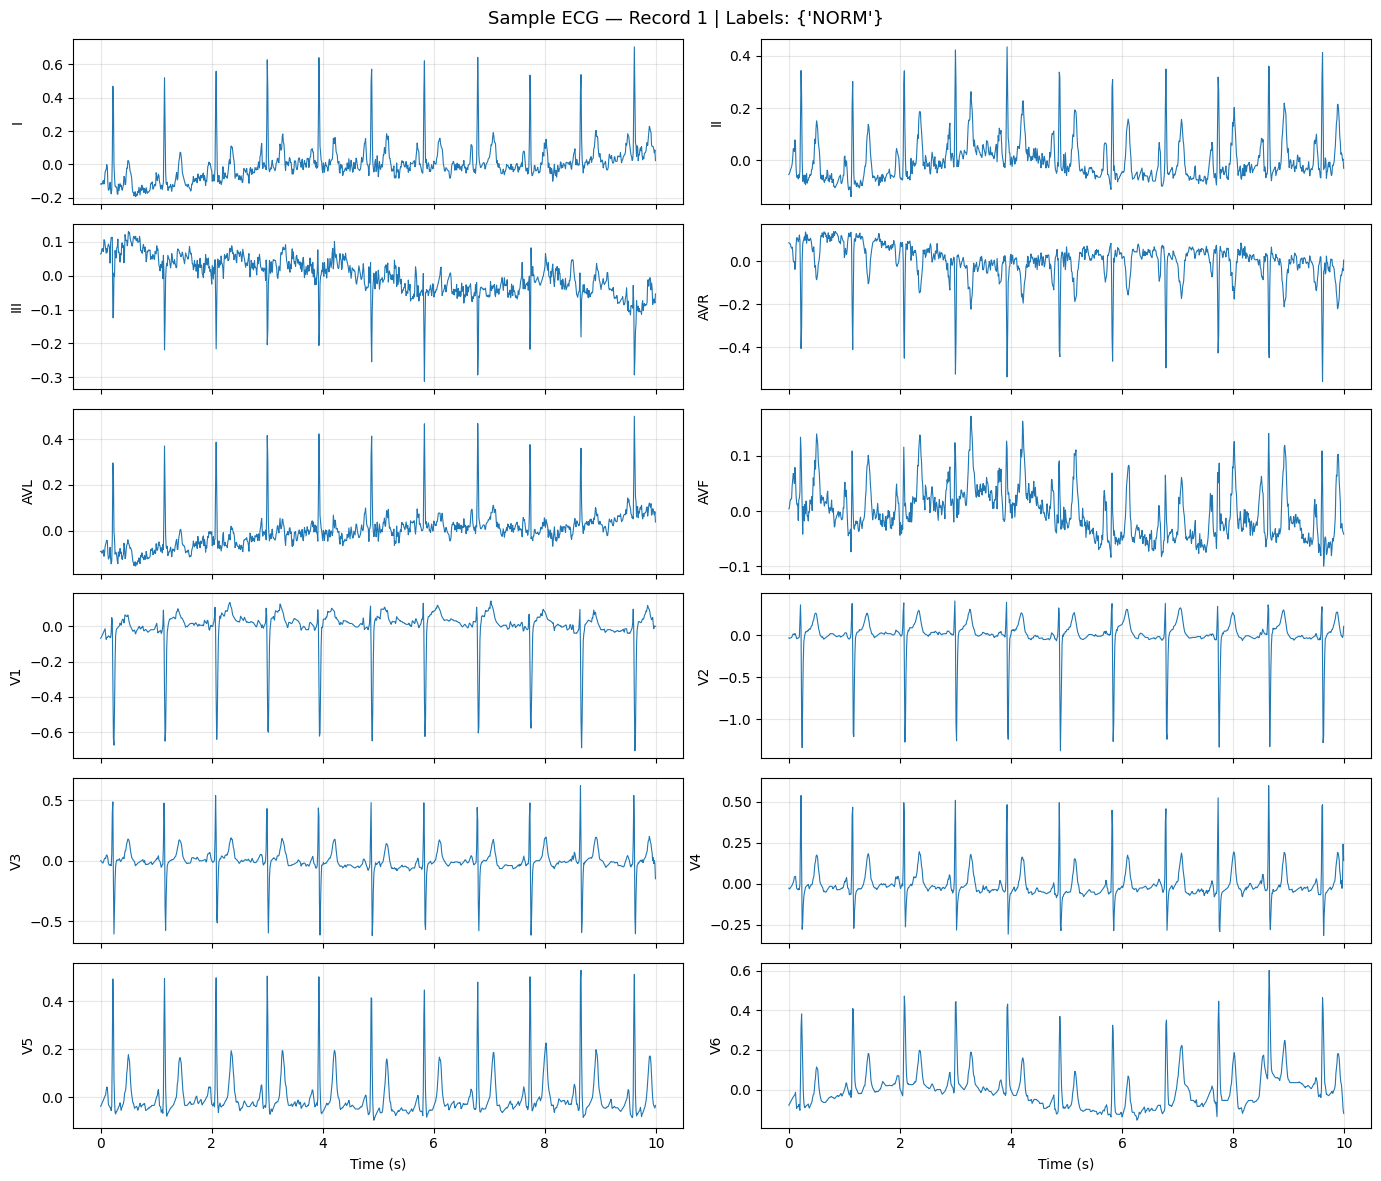

In [30]:
# Visualize a sample ECG (12 leads)
lead_names = ["I", "II", "III", "AVR", "AVL", "AVF", "V1", "V2", "V3", "V4", "V5", "V6"]
time_axis = np.arange(sample_signal.shape[0]) / 100  # seconds

fig, axes = plt.subplots(6, 2, figsize=(14, 12), sharex=True)
axes = axes.flatten()
for i, (ax, name) in enumerate(zip(axes, lead_names)):
    ax.plot(time_axis, sample_signal[:, i], linewidth=0.8)
    ax.set_ylabel(name, fontsize=10)
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (s)")
axes[-2].set_xlabel("Time (s)")
fig.suptitle(f"Sample ECG — Record {df.index[0]} | Labels: {df.iloc[0]['diagnostic_superclass']}", fontsize=13)
plt.tight_layout()
plt.show()

## 4. Load All Signals into a NumPy Array

In [31]:
# Load all 100Hz ECG signals — this may take a few minutes
# Result: X shape (21799, 1000, 12), Y shape (21799, 5)

def load_all_signals(df, base_path, sampling_rate=100):
    """Load all ECG signals into a single numpy array."""
    n = len(df)
    X = np.zeros((n, 1000, 12), dtype=np.float32)
    failed = []
    
    for i, (idx, row) in enumerate(tqdm(df.iterrows(), total=n, desc="Loading ECGs")):
        try:
            signal = load_ecg_signal(row["filename_lr"], base_path, sampling_rate)
            X[i] = signal
        except Exception as e:
            failed.append((idx, str(e)))
    
    if failed:
        print(f"\n⚠ Failed to load {len(failed)} records:")
        for ecg_id, err in failed[:5]:
            print(f"  ecg_id={ecg_id}: {err}")
    
    return X

X = load_all_signals(df, PATH_PTB)
Y = df[SUPERCLASSES].values.astype(np.float32)

print(f"\nX shape: {X.shape}  (records, timesteps, leads)")
print(f"Y shape: {Y.shape}  (records, superclasses: {SUPERCLASSES})")
print(f"X dtype: {X.dtype}, Y dtype: {Y.dtype}")
print(f"X memory: {X.nbytes / 1e9:.2f} GB")

Loading ECGs:   0%|          | 0/21799 [00:00<?, ?it/s]

Loading ECGs: 100%|██████████| 21799/21799 [01:36<00:00, 225.66it/s]


X shape: (21799, 1000, 12)  (records, timesteps, leads)
Y shape: (21799, 5)  (records, superclasses: ['NORM', 'MI', 'STTC', 'CD', 'HYP'])
X dtype: float32, Y dtype: float32
X memory: 1.05 GB


## 5. Train / Validation / Test Split (Fold-based)

In [32]:
# Mandatory split: Folds 1-8 = Train, Fold 9 = Val, Fold 10 = Test
folds = df["strat_fold"].values

train_mask = folds <= 8
val_mask   = folds == 9
test_mask  = folds == 10

X_train, Y_train = X[train_mask], Y[train_mask]
X_val,   Y_val   = X[val_mask],   Y[val_mask]
X_test,  Y_test  = X[test_mask],  Y[test_mask]

print(f"Train: {X_train.shape[0]:>6} samples")
print(f"Val:   {X_val.shape[0]:>6} samples")
print(f"Test:  {X_test.shape[0]:>6} samples")
print(f"Total: {X_train.shape[0] + X_val.shape[0] + X_test.shape[0]:>6}")

# Label distribution per split
print("\nLabel distribution per split:")
for name, y in [("Train", Y_train), ("Val", Y_val), ("Test", Y_test)]:
    counts = y.sum(axis=0).astype(int)
    print(f"  {name}: {dict(zip(SUPERCLASSES, counts))}")

Train:  17418 samples
Val:     2183 samples
Test:    2198 samples
Total:  21799

Label distribution per split:
  Train: {'NORM': np.int64(7596), 'MI': np.int64(4379), 'STTC': np.int64(4087), 'CD': np.int64(3907), 'HYP': np.int64(2119)}
  Val: {'NORM': np.int64(955), 'MI': np.int64(540), 'STTC': np.int64(515), 'CD': np.int64(495), 'HYP': np.int64(268)}
  Test: {'NORM': np.int64(963), 'MI': np.int64(550), 'STTC': np.int64(506), 'CD': np.int64(496), 'HYP': np.int64(262)}


## 6. Signal Preprocessing (Normalization)

In [33]:
# Per-lead standardization using training set statistics (zero-mean, unit-variance)
# Fit on train, apply to all splits

# Compute per-lead mean and std from training data
# X shape: (N, 1000, 12) → compute across axis 0 and 1
train_mean = X_train.mean(axis=(0, 1))  # shape: (12,)
train_std  = X_train.std(axis=(0, 1))   # shape: (12,)

# Avoid division by zero
train_std[train_std == 0] = 1.0

print("Per-lead training statistics:")
for i, name in enumerate(lead_names):
    print(f"  {name:>4}: mean={train_mean[i]:+.4f}, std={train_std[i]:.4f}")

# Normalize all splits
X_train_norm = (X_train - train_mean) / train_std
X_val_norm   = (X_val   - train_mean) / train_std
X_test_norm  = (X_test  - train_mean) / train_std

print(f"\nAfter normalization (train): mean≈{X_train_norm.mean():.4f}, std≈{X_train_norm.std():.4f}")

Per-lead training statistics:
     I: mean=-0.0017, std=0.1569
    II: mean=-0.0015, std=0.1602
   III: mean=+0.0002, std=0.1635
   AVR: mean=+0.0016, std=0.1359
   AVL: mean=-0.0009, std=0.1389
   AVF: mean=-0.0006, std=0.1415
    V1: mean=+0.0002, std=0.2304
    V2: mean=-0.0009, std=0.3313
    V3: mean=-0.0016, std=0.3273
    V4: mean=-0.0014, std=0.2918
    V5: mean=-0.0008, std=0.2672
    V6: mean=-0.0024, std=0.2758

After normalization (train): mean≈0.0000, std≈1.0216


## 7. Sanity Check — Visualize Normalized vs Raw Signal

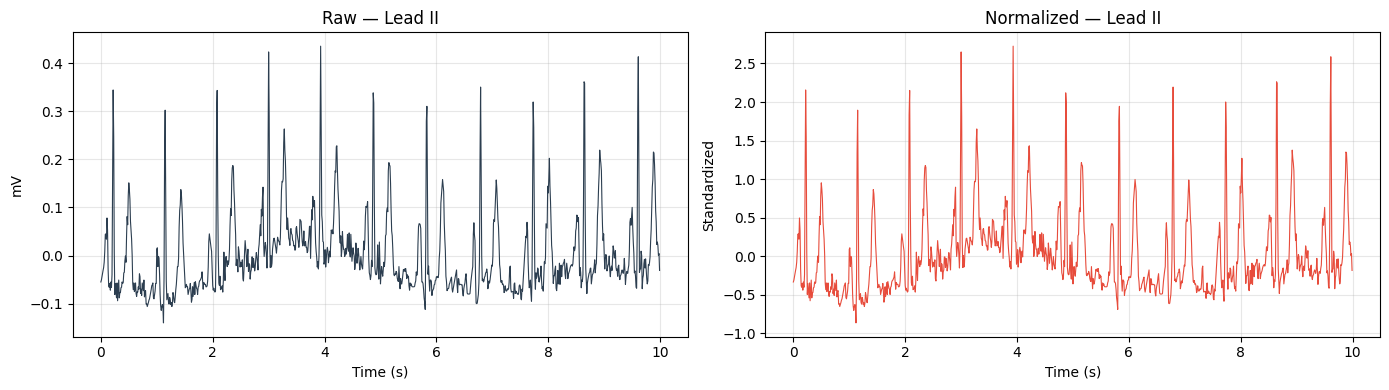

In [34]:
# Compare raw vs normalized for Lead II (index 1) of a train sample
idx = 0
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(time_axis, X_train[idx, :, 1], color="#2c3e50", linewidth=0.8)
axes[0].set_title("Raw — Lead II")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("mV")
axes[0].grid(True, alpha=0.3)

axes[1].plot(time_axis, X_train_norm[idx, :, 1], color="#e74c3c", linewidth=0.8)
axes[1].set_title("Normalized — Lead II")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Standardized")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Save Preprocessed Data

In [35]:
# Explore PTB-XL+ structure
print("PTB-XL+ contents:")
for item in os.listdir(PATH_PTB_PLUS):
    full = os.path.join(PATH_PTB_PLUS, item)
    if os.path.isdir(full):
        sub = os.listdir(full)
        print(f"  📁 {item}/ → {len(sub)} items  (e.g. {sub[:3]})")
    else:
        print(f"  📄 {item}")

# Check features directory structure
features_path = os.path.join(PATH_PTB_PLUS, "features")
print(f"\nFeatures subfolders:")
for f in sorted(os.listdir(features_path)):
    fp = os.path.join(features_path, f)
    if os.path.isdir(fp):
        files = os.listdir(fp)
        print(f"  📁 {f}/ → {len(files)} files  (e.g. {files[:2]})")
    else:
        print(f"  📄 {f}")

PTB-XL+ contents:
  📁 features/ → 5 items  (e.g. ['unig_features.csv', 'feature_description.csv', '12sl_features.csv'])
  📁 fiducial_points/ → 1 items  (e.g. ['ecgdeli'])
  📄 SHA256SUMS.txt
  📄 RECORDS
  📄 LICENSE.txt
  📁 median_beats/ → 2 items  (e.g. ['unig', '12sl'])
  📁 labels/ → 4 items  (e.g. ['mapping', 'ptbxl_statements.csv', 'snomed_description.csv'])

Features subfolders:
  📄 12sl_features.csv
  📄 ecgdeli_features.csv
  📄 feature_description.csv
  📁 old/ → 4 files  (e.g. ['unig_features.csv', 'feature_description.csv'])
  📄 unig_features.csv


In [36]:
# Load PTB-XL+ features
features_path = os.path.join(PATH_PTB_PLUS, "features")

# Feature description
feat_desc = pd.read_csv(os.path.join(features_path, "feature_description.csv"))
print(f"Feature descriptions: {feat_desc.shape}")
print(feat_desc.head(10).to_string())

print("\n" + "="*80)

# 12SL features (GE algorithm)
feat_12sl = pd.read_csv(os.path.join(features_path, "12sl_features.csv"), index_col="ecg_id")
print(f"\n12SL features: {feat_12sl.shape}")
print(f"Columns ({len(feat_12sl.columns)}): {list(feat_12sl.columns[:10])}...")

# UNIG features
feat_unig = pd.read_csv(os.path.join(features_path, "unig_features.csv"), index_col="ecg_id")
print(f"\nUNIG features: {feat_unig.shape}")
print(f"Columns ({len(feat_unig.columns)}): {list(feat_unig.columns[:10])}...")

# ECGDeli features
feat_ecgdeli = pd.read_csv(os.path.join(features_path, "ecgdeli_features.csv"), index_col="ecg_id")
print(f"\nECGDeli features: {feat_ecgdeli.shape}")
print(f"Columns ({len(feat_ecgdeli.columns)}): {list(feat_ecgdeli.columns[:10])}...")

# Check missing values
print(f"\n--- Missing values ---")
print(f"12SL:     {feat_12sl.isnull().sum().sum()} / {feat_12sl.size}")
print(f"UNIG:     {feat_unig.isnull().sum().sum()} / {feat_unig.size}")
print(f"ECGDeli:  {feat_ecgdeli.isnull().sum().sum()} / {feat_ecgdeli.size}")

Feature descriptions: (195, 10)
            id                                                         unig_feature                                 12sl_feature ecgdeli_feature                              description                                                                                           Loinc_concept_ids unit                       comment  consistent_units_unig  consistent_units_12sl
0      P_Amp_X                              $ P+_Amp_X if P_Morph_X>0 else P-_Amp_X                                 P_PeakAmpl_X           PWa_X               P wave amplitude in lead X  3024893, 3025405, 3026247, 3012776, 3027068, 3012976, 3010691, 3014384, 3025329, 3011867, 3025534, 3006830   mV                           NaN                  0.001                  0.001
1  P_DurFull_X                                                          ILM_P_Dur_X                           $ P_Dur_X+Pp_Dur_X           PWd_X  Sum of P and P' wave duration in lead X                                 

In [37]:
# Merge PTB-XL+ features with main dataframe
# Use ECGDeli features (open-source, most complete) as additional structured input
# Fill NaN with 0 for missing features, then normalize

feat_cols = feat_ecgdeli.columns.tolist()
df_features = df.join(feat_ecgdeli, how="left")

# Fill missing feature values with 0
df_features[feat_cols] = df_features[feat_cols].fillna(0)

# Extract feature arrays per split
F_all = df_features[feat_cols].values.astype(np.float32)
F_train = F_all[train_mask]
F_val   = F_all[val_mask]
F_test  = F_all[test_mask]

# Normalize features using training statistics
f_mean = F_train.mean(axis=0)
f_std  = F_train.std(axis=0)
f_std[f_std == 0] = 1.0

F_train_norm = (F_train - f_mean) / f_std
F_val_norm   = (F_val   - f_mean) / f_std
F_test_norm  = (F_test  - f_mean) / f_std

print(f"Feature matrix shape: {F_all.shape}")
print(f"F_train: {F_train_norm.shape}, F_val: {F_val_norm.shape}, F_test: {F_test_norm.shape}")
print(f"Feature columns: {len(feat_cols)}")
print(f"Sample features (first 5): {feat_cols[:5]}")

Feature matrix shape: (21799, 531)
F_train: (17418, 531), F_val: (2183, 531), F_test: (2198, 531)
Feature columns: 531
Sample features (first 5): ['PQ_Int_I', 'PQ_Int_I_iqr', 'PQ_Int_I_count', 'PQ_Int_II', 'PQ_Int_II_iqr']


In [47]:
# Save preprocessed arrays to Google Drive for fast reloading
save_dir = os.path.join(drive_path, "preprocessed")
os.makedirs(save_dir, exist_ok=True)

np.save(os.path.join(save_dir, "X_train.npy"), X_train_norm)
np.save(os.path.join(save_dir, "X_val.npy"),   X_val_norm)
np.save(os.path.join(save_dir, "X_test.npy"),  X_test_norm)
np.save(os.path.join(save_dir, "Y_train.npy"), Y_train)
np.save(os.path.join(save_dir, "Y_val.npy"),   Y_val)
np.save(os.path.join(save_dir, "Y_test.npy"),  Y_test)
np.save(os.path.join(save_dir, "F_train.npy"), F_train_norm)
np.save(os.path.join(save_dir, "F_val.npy"),   F_val_norm)
np.save(os.path.join(save_dir, "F_test.npy"),  F_test_norm)

# Also save metadata
import json
metadata = {
    "superclasses": SUPERCLASSES,
    "n_features": len(feat_cols),
    "signal_shape": [1000, 12],
    "train_size": int(X_train_norm.shape[0]),
    "val_size": int(X_val_norm.shape[0]),
    "test_size": int(X_test_norm.shape[0]),
    "lead_names": ["I", "II", "III", "AVR", "AVL", "AVF", "V1", "V2", "V3", "V4", "V5", "V6"],
}
with open(os.path.join(save_dir, "metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

print(f"✓ Saved to: {save_dir}")
print(f"Files: {os.listdir(save_dir)}")

✓ Saved to: drive/MyDrive/ECG/preprocessed
Files: ['X_train.npy', 'X_val.npy', 'X_test.npy', 'Y_train.npy', 'Y_val.npy', 'Y_test.npy', 'F_train.npy', 'F_val.npy', 'F_test.npy', 'metadata.json']


## Summary

All preprocessed data saved to Google Drive at `drive_path/preprocessed/`.

**Saved files:**
- `X_train.npy`, `X_val.npy`, `X_test.npy` — Normalized 12-lead ECG signals (1000 timesteps × 12 leads)
- `Y_train.npy`, `Y_val.npy`, `Y_test.npy` — Multi-label targets (5 superclasses)
- `F_train.npy`, `F_val.npy`, `F_test.npy` — Normalized PTB-XL+ ECGDeli features
- `metadata.json` — Superclass names, shapes, split sizes

**Next:** Open `train.ipynb` to build and train the model (use GPU runtime).